# SHAP Diagnostics Notebook

This notebook loads the project artifacts and runs a SHAP-based explainability workflow for the trained models.

In [1]:
from pathlib import Path
import sys
import os

notebook_dir = Path.cwd().resolve()
repo_root = notebook_dir.parent if notebook_dir.name == 'notebooks' else notebook_dir
src_dir = repo_root / 'src'
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

try:
    import pandas as pd
    import numpy as np
    import shap
    import matplotlib.pyplot as plt
except ModuleNotFoundError:
    %pip install -r "{repo_root / 'requirements.txt'}"
    import pandas as pd
    import numpy as np
    import shap
    import matplotlib.pyplot as plt

repo_root

c:\Users\Nasim\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


WindowsPath("C:/Users/Nasim/OneDrive/Desktop/COMPAS Research Datasets/IEEE COMPAS '26")

In [2]:
# Review the available documentation and source files
for filename in ['README.md', 'ARCHITECTURE.md', 'requirements.txt']:
    path = repo_root / filename
    if path.exists():
        print(f'\n===== {filename} =====')
        print(path.read_text(encoding='utf-8'))


===== README.md =====
# Beyond Accuracy: Diagnosing Systematic Biases in Classical ML Weather Models Using SHAP Explainability

This repository contains the replication code and experimental pipeline for auditing classical machine learning weather models predicting precipitation and near-surface air temperature (T2M) for Dhaka, Bangladesh, using 45 years (1981–2025) of NASA POWER reanalysis data.

## Project Architecture
* `data/`: Contains raw climate matrix data and formatted time-series outputs.
* `src/`: Modular Python pipeline implementing data engineering, model suites, and TreeSHAP diagnostics.
* `figures/`: Publication-grade, 300 DPI visual outputs (Beeswarm and seasonal dependence plots).

## Installation & Setup
1. Clone the repository and navigate to the project root.
2. Install the necessary dependencies:
   ```bash
   pip install -r requirements.txt

===== ARCHITECTURE.md =====
IEEE COMPAS '26/
│
├── data/
│   ├── raw/                 # Store the original 'data.csv' here 

In [3]:
# Load the processed data if it exists
processed_path = repo_root / 'data' / 'processed' / 'df_processed.csv'
if processed_path.exists():
    df = pd.read_csv(processed_path, parse_dates=['DATE'], index_col='DATE')
    print(df.head())
    print('\nColumns:', list(df.columns))
else:
    print('Processed data not found. Run the preprocessing script first.')

            ALLSKY_SFC_SW_DWN  CLOUD_AMT  PRECTOTCORR      PS   QV2M    T2M  \
DATE                                                                          
1984-01-01             4.0250      26.21         0.11  101.28   5.43  18.71   
1984-02-01             4.6531      34.29         0.01  101.13   4.71  21.31   
1984-03-01             5.7031      30.38         0.01  100.71   6.38  28.18   
1984-04-01             5.7763      58.32         0.75  100.34  12.87  32.43   
1984-05-01             5.1067      72.58         8.27  100.10  18.15  30.17   

               TS  WS10M_MIN   WSC       SEASON  T2M_LAG_1  PRECTOTCORR_LAG_1  
DATE                                                                           
1984-01-01  18.60       0.21  1.76          Dry      19.33               0.20  
1984-02-01  21.90       0.23  2.12          Dry      18.71               0.11  
1984-03-01  28.47       0.30  2.06  Pre-Monsoon      21.31               0.01  
1984-04-01  34.07       0.19  2.56  Pre-Monsoo

In [4]:
# Prepare a simple test split for explainability
if 'df' in locals():
    target_name = 'T2M' if 'T2M' in df.columns else (df.columns[0] if len(df.columns) > 0 else None)
    if target_name is not None:
        test = df[df.index.year >= 2015]
        feature_columns = [col for col in df.columns if col not in {target_name, 'SEASON'}]
        X_test = test[feature_columns]
        print('Target:', target_name)
        print('Feature columns:', feature_columns)

Target: T2M
Feature columns: ['ALLSKY_SFC_SW_DWN', 'CLOUD_AMT', 'PRECTOTCORR', 'PS', 'QV2M', 'TS', 'WS10M_MIN', 'WSC', 'T2M_LAG_1', 'PRECTOTCORR_LAG_1']


In [5]:
# Load a trained model if present
model_dir = repo_root / 'models'
if model_dir.exists():
    print('Available model artifacts:')
    for path in sorted(model_dir.glob('*')):
        print(' -', path.name)
else:
    print('No model directory found yet.')

Available model artifacts:
 - CatBoost_PRECTOTCORR.pkl
 - CatBoost_T2M.pkl
 - DecisionTree_PRECTOTCORR.pkl
 - DecisionTree_T2M.pkl
 - LightGBM_PRECTOTCORR.pkl
 - LightGBM_T2M.pkl
 - LinearRegression_PRECTOTCORR.pkl
 - LinearRegression_T2M.pkl
 - RandomForest_PRECTOTCORR.pkl
 - RandomForest_T2M.pkl
 - scaler_PRECTOTCORR.pkl
 - scaler_T2M.pkl
 - XGBoost_PRECTOTCORR.pkl
 - XGBoost_T2M.pkl


In [6]:
# A lightweight SHAP example using a simple model if available
if 'X_test' in locals() and 'target_name' in locals():
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.preprocessing import StandardScaler
    
    y_test = test[target_name]
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(scaler.fit_transform(X_test), columns=X_test.columns, index=X_test.index)
    model = RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)
    model.fit(X_scaled, y_test)
    explainer = shap.Explainer(model, X_scaled)
    shap_values = explainer(X_scaled.iloc[-500:])
    print('SHAP values computed successfully.')

SHAP values computed successfully.


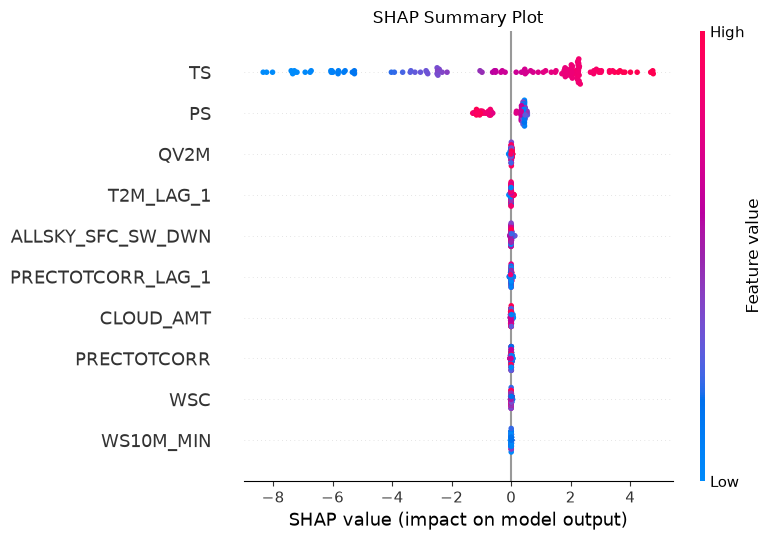

In [7]:
# Plot a summary figure when SHAP values are available
if 'shap_values' in locals():
    plt.figure(figsize=(8, 4))
    shap.plots.beeswarm(shap_values, max_display=10, show=False)
    plt.title('SHAP Summary Plot')
    plt.tight_layout()
    plt.show()